In [1]:
%pylab inline
import gc
import os
import glob
import numpy as np

import matplotlib
import matplotlib.pyplot as plt

import astropy.io.fits as pyfits
import astropy.table as astTable

import sim_analysis_utilities as utilities

Populating the interactive namespace from numpy and matplotlib


In [ ]:
def get_FDFC_flag(ra,dec,version='s19',degree=True):
    # Read fdfc file
    datDir='/gpfs02/work/xiangchong.li/S19ACatalogs/'
    hpfname =   os.path.join(datDir,hpfname,"s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits") 
    m       =   hp.read_map(hpfname, nest = True, dtype = np.bool)

    # Get flag
    if degree:
        mfactor =   np.pi/180.
    else:
        mfactor =   1.
    indices_map =   np.where(m)[0]
    nside   =   hp.get_nside(m)
    phi     =   ra*mfactor
    theta   =   np.pi/2. - dec*mfactor
    indices_obj = hp.ang2pix(nside, theta, phi, nest = True)
    return np.in1d(indices_obj, indices_map)

In [3]:
version='v2'
dataDir='/gpfs02/work/miyatake/S19A/S19A_star_mask_g15/'
nomDir='/gpfs02/work/xiangchong.li/S19ACatalogs/%s/catalog_obs_reGaus_no_m/' %version
outDir0='/gpfs02/work/xiangchong.li/S19ACatalogs/%s/catalog_tracts/' %version
outDir1='/gpfs02/work/xiangchong.li/S19ACatalogs/%s/catalog_others/' %version
if not os.path.isdir(outDir0):
    os.mkdir(outDir0)
if not os.path.isdir(outDir1):
    os.mkdir(outDir1)

# poz

In [33]:
for fieldname in utilities.field_names: 
    fnamelist=glob.glob(os.path.join(dataDir,'%s_tracts/*_pz.fits' %fieldname))
    outDir=os.path.join(outDir0,'%s_tracts/' %fieldname)
    if not os.path.isdir(outDir):
        os.mkdir(outDir)
    for fname in fnamelist:
        tract=fname.split('/')[-1].split('_')[0]
        fname=os.path.join(dataDir,'%s_tracts/%s.fits' %(fieldname,tract))
        pnamed=os.path.join(dataDir,'%s_tracts/%s_pz_pdf_demp.fits' %(fieldname,tract))
        pnamem=os.path.join(dataDir,'%s_tracts/%s_pz_pdf_mizuki.fits' %(fieldname,tract))
        pname=os.path.join(dataDir,'%s_tracts/%s_pz.fits' %(fieldname,tract))
        assert os.path.isfile(fname)
        assert os.path.isfile(pname)
        assert os.path.isfile(pnamed)
        assert os.path.isfile(pnamem)
        
        data=pyfits.getdata(fname)
        pata=pyfits.getdata(pname)
        patad=pyfits.getdata(pnamed)
        patam=pyfits.getdata(pnamem)
        wlflag=utilities.update_wl_flags(data)['weak_lensing_flag']
        
        data=data[wlflag]
        pata=pata[wlflag]
        patad=patad[wlflag]
        patam=patam[wlflag]
        
        foame=os.path.join(outDir,'%s.fits' %(tract))
        poame=os.path.join(outDir,'%s_pz.fits' %(tract))
        poamed=os.path.join(outDir,'%s_pz_pdf_demp.fits' %(tract))
        poamem=os.path.join(outDir,'%s_pz_pdf_mizuki.fits' %(tract))
        
        pyfits.writeto(foame,data,overwrite=True)
        pyfits.writeto(poame,pata,overwrite=True)
        pyfits.writeto(poamem,patam,overwrite=True)
        pyfits.writeto(poamed,patad,overwrite=True)
        del data
        del pata
        del patad
        del patam
        gc.collect()

/work/xiangchong.li/code/FPFS_Private/FPFSBASE/python/sim_analysis_utilities.py:1765: RuntimeWarning: invalid value encountered in less
  (get_imag_A10(catalog)<25.5)& \


In [20]:
fieldname='GAMA09H'

fieldDir=os.path.join(outDir0,fieldname)
tractList=[9071,9072,9314,9315]
for tract in tractList:
    fname=os.path.join(fieldDir,'%s.fits' %(tract))
    pname=os.path.join(fieldDir,'%s_pz.fits' %(tract))
    pnamed=os.path.join(fieldDir,'%s_pz_pdf_demp.fits' %(tract))
    pnamem=os.path.join(fieldDir,'%s_pz_pdf_mizuki.fits' %(tract))
    
    assert os.path.isfile(fname)
    assert os.path.isfile(pname)
    assert os.path.isfile(pnamed)
    assert os.path.isfile(pnamem)
    
    data=pyfits.getdata(fname)
    pata=pyfits.getdata(pname)
    patad=pyfits.getdata(pnamed)
    patam=pyfits.getdata(pnamem)
    mask=utilities.get_mask_visit_104994(data)
    wlflag=utilities.update_wl_flags(data)['weak_lensing_flag']
    mask = mask&wlflag
    
    data=data[mask]
    pata=pata[mask]
    patad=patad[mask]
    patam=patam[mask]
    
    pyfits.writeto(fname,data,overwrite=True)
    pyfits.writeto(pname,pata,overwrite=True)
    pyfits.writeto(pnamem,patam,overwrite=True)
    pyfits.writeto(pnamed,patad,overwrite=True)
    

In [24]:
fieldname='GAMA09H'
fieldDir=os.path.join(outDir0,fieldname)
dataA=pyfits.getdata('/gpfs02/work/xiangchong.li/S19ACatalogs/catalog_obs_reGaus_no_m/%s_no_m.fits' %fieldname)
tractList=[9071,9072,9314,9315]
for tract in tractList:
    fname=os.path.join(fieldDir,'%s.fits' %(tract))    
    data=pyfits.getdata(fname)
    assert len(data)==np.sum(dataA['tract']==tract)
    

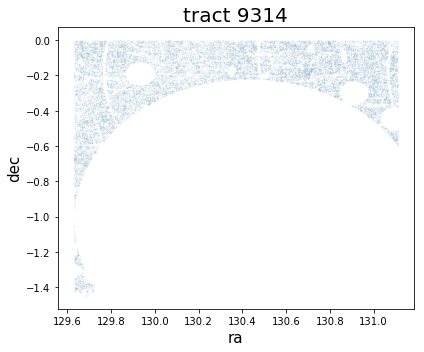

In [21]:
tract=9314
fname=os.path.join(fieldDir,'%s.fits' %(tract))
pname=os.path.join(fieldDir,'%s_pz.fits' %(tract))
pnamed=os.path.join(fieldDir,'%s_pz_pdf_demp.fits' %(tract))
pnamem=os.path.join(fieldDir,'%s_pz_pdf_mizuki.fits' %(tract))
    
    
data=pyfits.getdata(fname)
pata=pyfits.getdata(pname)
patad=pyfits.getdata(pnamed)
patam=pyfits.getdata(pnamem)
assert len(data)==len(pata)
assert len(data)==len(patad)
assert len(data)==len(patam)

ra=data['i_ra']
dec=data['i_dec']
fig=plt.figure(figsize=(6,5))
plt.title('tract %s' %tract,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

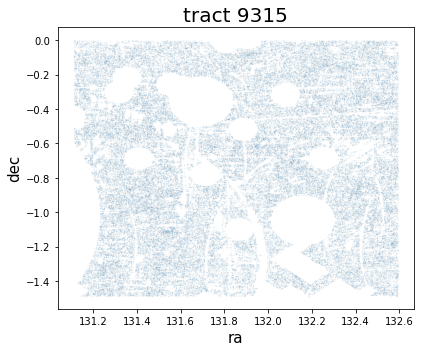

In [22]:
tract=9315
fname=os.path.join(fieldDir,'%s.fits' %(tract))
pname=os.path.join(fieldDir,'%s_pz.fits' %(tract))
pnamed=os.path.join(fieldDir,'%s_pz_pdf_demp.fits' %(tract))
pnamem=os.path.join(fieldDir,'%s_pz_pdf_mizuki.fits' %(tract))
    
    
data=pyfits.getdata(fname)
pata=pyfits.getdata(pname)
patad=pyfits.getdata(pnamed)
patam=pyfits.getdata(pnamem)
assert len(data)==len(pata)
assert len(data)==len(patad)
assert len(data)==len(patam)

ra=data['i_ra']
dec=data['i_dec']
fig=plt.figure(figsize=(6,5))
plt.title('tract %s' %tract,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

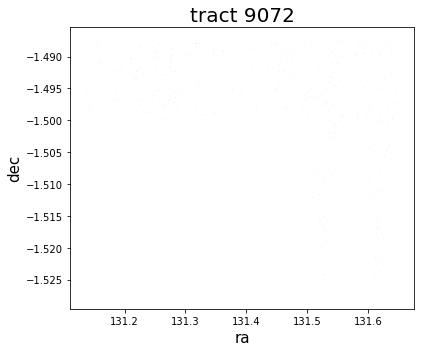

In [16]:
tract=9072
fname=os.path.join(fieldDir,'%s.fits' %(tract))
pname=os.path.join(fieldDir,'%s_pz.fits' %(tract))
pnamed=os.path.join(fieldDir,'%s_pz_pdf_demp.fits' %(tract))
pnamem=os.path.join(fieldDir,'%s_pz_pdf_mizuki.fits' %(tract))
    
    
data=pyfits.getdata(fname)
pata=pyfits.getdata(pname)
patad=pyfits.getdata(pnamed)
patam=pyfits.getdata(pnamem)
assert len(data)==len(pata)
assert len(data)==len(patad)
assert len(data)==len(patam)

ra=data['i_ra']
dec=data['i_dec']
fig=plt.figure(figsize=(6,5))
plt.title('tract %s' %tract,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [79]:
# The second HDU
for fieldname in utilities.field_names: 
    fnamelist=glob.glob(os.path.join(dataDir,'%s_tracts/*_pz.fits' %fieldname))
    outDir=os.path.join(outDir0,'%s_tracts/' %fieldname)
    if not os.path.isdir(outDir):
        os.mkdir(outDir)
    for fname in fnamelist:
        tract=fname.split('/')[-1].split('_')[0]
        pnamed=os.path.join(dataDir,'%s_tracts/%s_pz_pdf_demp.fits' %(fieldname,tract))
        patade=pyfits.open(pnamed)[2]
        poamed=os.path.join(outDir,'%s_pz_pdf_demp.fits' %(tract))
        assert os.path.isfile(poamed)
        potad=pyfits.open(poamed)
        potad.append(patade)
        potad.writeto(poamed,overwrite=True)
        del potad
        del patade
        del poamed
        gc.collect()
        
        pnamem=os.path.join(dataDir,'%s_tracts/%s_pz_pdf_mizuki.fits' %(fieldname,tract))
        patame=pyfits.open(pnamem)[2]
        poamem=os.path.join(outDir,'%s_pz_pdf_mizuki.fits' %(tract))
        assert os.path.isfile(poamem)
        potam=pyfits.open(poamem)
        potam.append(patame)
        potam.writeto(poamem,overwrite=True)
        del potam
        del patame
        del poamem
        gc.collect()

In [77]:
print(len(potad[2].data)==len(potad[1].data['PDF'][0]))
print(len(potam[2].data)==len(potam[1].data['PDF'][0]))

True
True


# photo-z

In [5]:
for fieldname in utilities.field_names: 
    datain=astTable.Table.read(os.path.join(dataDir,'%s_pz.fits' %fieldname))
    nomIds=astTable.Table.read(os.path.join(nomDir,'%s_no_m.fits' %fieldname))['object_id']
    nomIds=astTable.Table([nomIds])
    aa=nomIds['object_id']
    aa.sort()
    assert np.all(aa==nomIds['object_id']), 'not sorted'
    dataout=astTable.join(left=nomIds,right=datain,keys='object_id',join_type='left',uniq_col_name='object_id')
    dataout.write(os.path.join(outDir1,'%s_pz.fits' %fieldname),overwrite=True)
    del dataout
    del aa
    del datain
    gc.collect()

In [6]:
for fieldname in utilities.field_names: 
    data1=astTable.Table.read(os.path.join(outDir1,'%s_pz.fits' %fieldname))
    data2=astTable.Table.read(os.path.join(nomDir,'%s_no_m.fits' %fieldname))
    assert np.all(data1['object_id']==data2['object_id'])
    del data1
    del data2
    gc.collect()